# Heart Disease Prediction — Step 5: Unsupervised Clustering (Bonus Analysis)

Everything before this step, and everything after it, is **supervised learning** — the model learns
from labeled data (we tell it who has heart disease and who doesn't).

This notebook is a small, separate **unsupervised learning** exploration: we ask whether patients
naturally group into distinct clusters based on their health measurements alone, **without ever
telling the algorithm who actually has heart disease.** Afterwards, we peek at the real labels just
to see whether the clusters happened to line up with disease risk.

This is a genuinely different question from the rest of the project: not 'can we predict disease?' but
'do patients naturally form distinct groups, and does that grouping mean anything?'

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42

X_train_scaled = pd.read_csv('X_train_scaled.csv')
X_test_scaled = pd.read_csv('X_test_scaled.csv')
y_train = pd.read_csv('y_train.csv').squeeze()
y_test = pd.read_csv('y_test.csv').squeeze()

# Use every patient (train + test combined) since clustering isn't about predicting new patients,
# it's about understanding structure in the data we have
X_all = pd.concat([X_train_scaled, X_test_scaled], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)

print("Total patients for clustering:", X_all.shape[0])

Total patients for clustering: 894


## 1. Why K-Means, and why scaled data?

**K-Means** groups patients by repeatedly assigning each one to whichever of *k* cluster centers is
closest, then moving each center to the average of its assigned patients, until the groups stop
changing. It's the most widely used clustering algorithm, and a natural fit here since all our
features are numeric.

We use the **scaled** features (the same ones prepared in preprocessing) because K-Means measures
distance between patients — without scaling, a feature like `chol` (values in the hundreds) would
dominate the distance calculation over a feature like `oldpeak` (values under 7), just because of its
size, not because it actually matters more.

## 2. How many clusters should we use?

We don't just guess a number — we use the **elbow method**: try a range of cluster counts, and for
each one measure how tightly grouped the patients are within their assigned cluster (inertia). We're
looking for the point where adding more clusters stops giving a meaningful improvement — the 'elbow'
in the plot.

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

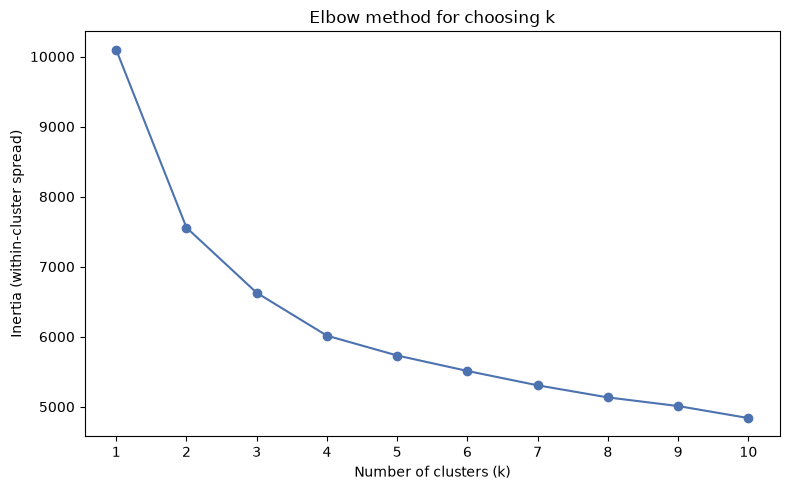

In [2]:
inertias = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_all)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertias, marker='o', color='#4C72B0')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (within-cluster spread)')
plt.title('Elbow method for choosing k')
plt.xticks(list(k_range))
plt.tight_layout()
plt.show()

In [3]:
# Cross-check with silhouette score (higher = better-separated clusters), for k = 2 to 6
sil_scores = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_all)
    sil_scores[k] = silhouette_score(X_all, labels)

for k, score in sil_scores.items():
    print(f"k={k}: silhouette score = {score:.3f}")

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

k=2: silhouette score = 0.356
k=3: silhouette score = 0.186
k=4: silhouette score = 0.184
k=5: silhouette score = 0.154
k=6: silhouette score = 0.138


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


**Decision:** we'll go with **k = 2** — the elbow plot doesn't show a dramatic bend at any single
point (common in real, messy medical data), but k=2 has the strongest silhouette score, and it also
conveniently lets us directly compare 'the two natural clusters the data forms' against 'the two actual
diagnosis groups' in a straightforward way.

## 3. Run K-Means with k = 2

In [4]:
kmeans = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_all)

X_all_with_clusters = X_all.copy()
X_all_with_clusters['cluster'] = cluster_labels
X_all_with_clusters['actual_target'] = y_all.values

print(pd.Series(cluster_labels).value_counts().rename('patients per cluster'))

0    755
1    139
Name: patients per cluster, dtype: int64


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


## 4. Visualizing the clusters

Our data has 13 features, far too many to plot directly. We use **PCA (Principal Component
Analysis)** to compress it down to 2 dimensions that capture as much of the original variation as
possible, purely so we can see the clusters on a 2D chart. PCA is only used here for visualization —
it isn't used anywhere else in the pipeline.

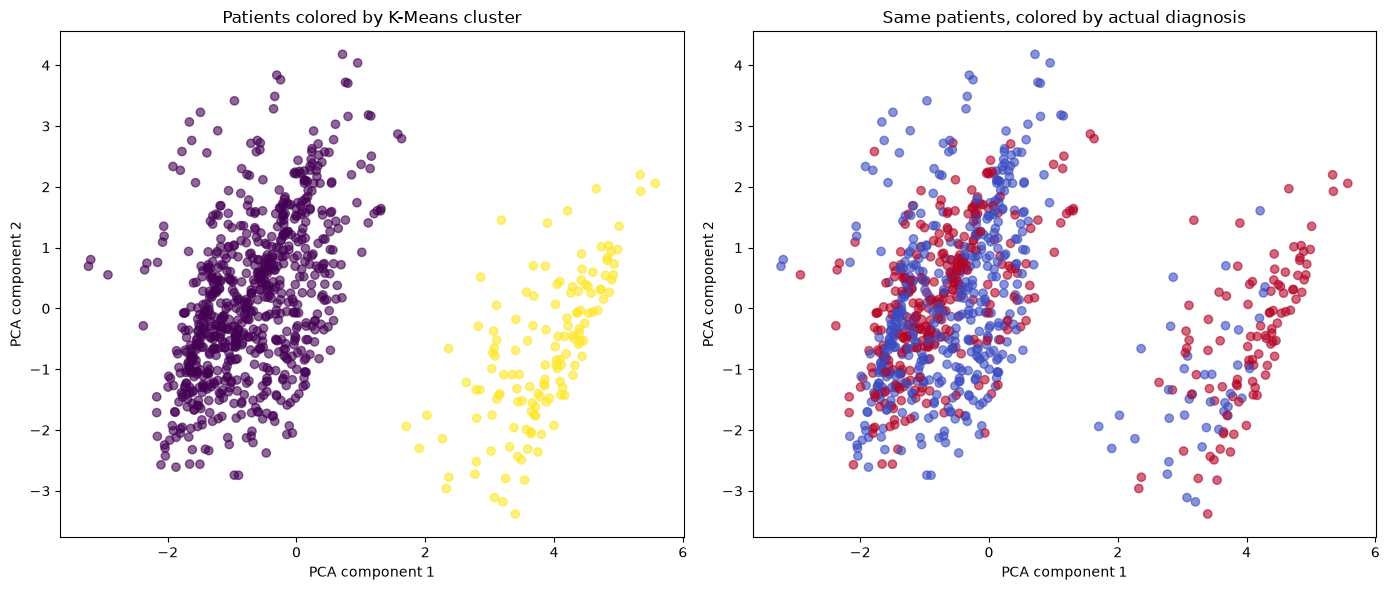

These 2 components capture 44.4% of the original variation in the data


In [5]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_all)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6)
axes[0].set_title('Patients colored by K-Means cluster')
axes[0].set_xlabel('PCA component 1')
axes[0].set_ylabel('PCA component 2')

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_all, cmap='coolwarm', alpha=0.6)
axes[1].set_title('Same patients, colored by actual diagnosis')
axes[1].set_xlabel('PCA component 1')
axes[1].set_ylabel('PCA component 2')

plt.tight_layout()
plt.show()

print(f"These 2 components capture {pca.explained_variance_ratio_.sum():.1%} of the original variation in the data")

**How to read this:** if unsupervised clustering (left) and actual diagnosis (right) produced
similar-looking patterns, that would suggest the natural structure in the data lines up with disease
status. If they look quite different, it means the clusters are picking up on some other pattern in
the data — not necessarily disease status.

## 5. Do the clusters actually line up with real diagnosis?

Now we check — for real — whether the two clusters the algorithm found on its own turned out to
roughly match the two real diagnosis groups.

In [6]:
crosstab = pd.crosstab(X_all_with_clusters['cluster'], X_all_with_clusters['actual_target'],
                        rownames=['K-Means Cluster'], colnames=['Actual Diagnosis'])
crosstab.columns = ['No disease', 'Disease']
crosstab.index = ['Cluster 0', 'Cluster 1']
crosstab

,No disease,Disease
Cluster 0,458,297
Cluster 1,39,100


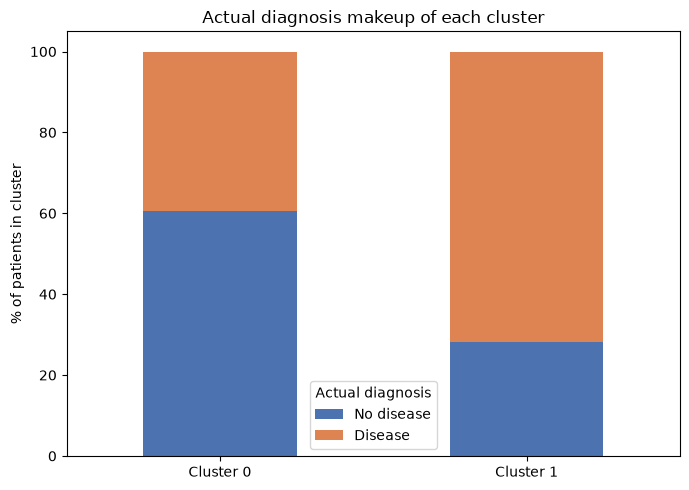

In [7]:
crosstab_pct = crosstab.div(crosstab.sum(axis=1), axis=0) * 100

crosstab_pct.plot(kind='bar', stacked=True, figsize=(7, 5), color=['#4C72B0', '#DD8452'])
plt.ylabel('% of patients in cluster')
plt.title('Actual diagnosis makeup of each cluster')
plt.xticks(rotation=0)
plt.legend(title='Actual diagnosis')
plt.tight_layout()
plt.show()

## 6. What do the two clusters actually represent, if not diagnosis?

Since the clusters don't perfectly match disease status, it's worth checking what does separate them —
they may be capturing a different, still-meaningful pattern (e.g. an age/risk-profile split).

In [8]:
cluster_profile = X_all_with_clusters.drop(columns=['actual_target']).groupby('cluster').mean().round(2)
cluster_profile

,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal
cluster,,,,,,,,,,,,,
0,-0.05,0.67,1.53,-0.05,-0.02,0.12,0.51,0.02,0.30,-0.07,1.60,0.42,2.35
1,0.23,0.86,2.41,0.07,0.04,0.16,0.90,-0.19,0.49,0.38,1.81,0.80,6.83


## Summary

- Used **K-Means (k=2)**, chosen via the elbow method and silhouette score, on the same scaled
  features used throughout the project — entirely without using the disease label
- The two clusters are **unequal in size** (755 vs 139 patients) and don't perfectly separate
  patients by diagnosis — but they aren't meaningless either: **Cluster 1 has a 71.9% disease rate,
  compared to 39.3% in Cluster 0.** So while clustering wasn't given the diagnosis label, it still
  landed on groupings that meaningfully differ in disease prevalence.
- Looking at what separates the two clusters: Cluster 1 patients have, on average, higher `cp`
  (chest pain severity), `thal`, `ca`, `oldpeak`, and `exang` values — the same features SHAP later
  identifies as most important to the *supervised* model. That's a nice, honest cross-check between
  the two completely different techniques landing on similar signals.
- This demonstrates a genuinely different analytical technique (unsupervised learning) alongside the
  project's core supervised approach, and adds a small independent piece of evidence that these
  clinical features carry real signal — without changing the project's main objective or final model

The rest of the pipeline (supervised model training, tuning, evaluation, SHAP) does not depend on
anything in this notebook — this was a standalone exploration.